# 06b — The decoder decides: hand-built graph against the full error model

**Result.** On the same Selene shots, the decoder changes the logical error rate by up to 7×,
and changes the shape of the curve. The hand-built phenomenological graph (the decoder of the
original 06 and of the retired 07) reproduces the original 06 sweep exactly; decoding the same shots with
the full detector error model of the verified Stim copy (06a) gives:

| Δt | 1 | 2 | 4 | 8 | 12 | 16 | 24 | 32 |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| hand-built graph | 0.2162 | 0.1204 | 0.0751 | 0.0434 | 0.0310 | 0.0264 | 0.0221 | 0.0199 |
| full error model | 0.0309 | 0.0187 | 0.0138 | 0.0127 | 0.0118 | 0.0124 | 0.0136 | 0.0138 |
| ratio | 7.0 | 6.4 | 5.4 | 3.4 | 2.6 | 2.1 | 1.6 | 1.4 |

The full error model does better in all 50 blocks. At d = 5 (§4) the same holds in all 368
blocks, with a larger gap: 8.1× at Δt = 1 falling to 3.0× at Δt = 16. The hand-built graph's curve falls all the
way to the largest Δt, which is what led the original 06 to report no interior optimum; the
full error model's curve has its minimum at Δt = 12 (06c). **06c therefore uses the full error
model.**

## 0. Setup

Selene's memory experiment (`surface_memory.Geometry`): rotated d = 3, Δt idle ops then a full
extraction round of both check sectors, repeated `N = 96/Δt` times (total idle fixed at 96),
`p_1q = 0.0005`, `p_meas = 0.002`, 5 blocks × 10,000 shots per Δt (Selene shot offsets
0, 10,000, … at seed 1). These are the original 06 sweep's shots exactly.

The shots are stored as detection events and logical observables
(`qec_timing.circuit_level.memory_shots`, under `results/circuit_level/cache/`), so every
decoder below reads the same bits and no Selene run is repeated.

In [1]:
import sys, pathlib, time, collections
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
plt.rcParams['mathtext.fontset'] = 'cm'   # LaTeX-style math in figure labels

sys.path.insert(0, '../src')
from qec_timing.circuit_level.surface_memory import Geometry
from qec_timing.circuit_level import selene_mirror as sm, memory_shots, runcache

pd.set_option('display.width', 160)
BLUE, ORANGE, AQUA, GRAY, INK, MUTED = '#2a78d6', '#eb6834', '#1baf7a', '#8a8a86', '#0b0b0b', '#52514e'
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.edgecolor': '#c9c9c4', 'axes.labelcolor': MUTED, 'axes.titlesize': 10,
                     'axes.labelsize': 9, 'xtick.color': MUTED, 'ytick.color': MUTED,
                     'xtick.labelsize': 8, 'ytick.labelsize': 8, 'grid.color': '#e6e6e1',
                     'legend.frameon': False, 'legend.fontsize': 8, 'font.size': 9, 'text.color': INK})
FIGDIR = pathlib.Path('figures'); FIGDIR.mkdir(exist_ok=True)


def finish(fig, name):
    fig.tight_layout()
    fig.savefig(FIGDIR / f'{name}.png', bbox_inches='tight', facecolor='white')
    plt.show()

def tau_axes(ax, ticks):
    ax.set_xscale('log', base=2); ax.set_yscale('log')
    ax.set_xticks(ticks); ax.get_xaxis().set_major_formatter(plt.ScalarFormatter())
    ax.get_xaxis().set_minor_formatter(plt.NullFormatter())
    ax.grid(alpha=.6, which='both'); ax.set_axisbelow(True)

CODE, DISTANCE = 'rotated', 3
TOTAL_IDLE, P_1Q, P_MEAS = 96, 0.0005, 0.002
SHOTS, BLOCKS = 10_000, 5
TAUS = [t for t in range(1, TOTAL_IDLE + 1) if TOTAL_IDLE % t == 0 and TOTAL_IDLE // t >= DISTANCE]
G = Geometry(CODE, DISTANCE)


def shots(tau, k):
    return memory_shots.get(G, tau, TOTAL_IDLE // tau, SHOTS, offset=k * SHOTS, seed=1,
                            p_1q=P_1Q, p_meas=P_MEAS)


print("tau grid:", TAUS, " rounds:", [TOTAL_IDLE // t for t in TAUS])

tau grid: [1, 2, 3, 4, 6, 8, 12, 16, 24, 32]  rounds: [96, 48, 32, 24, 16, 12, 8, 6, 4, 3]


## 1. The two decoders

**Hand-built graph** (`Geometry.matching` with `Geometry.priors`; the decoder the original 06 and the retired 07 used).
The paper's phenomenological picture written as a matching graph: a data fault flips the
Z-checks containing that qubit in the same round (space-like or boundary edges), a readout
fault flips the same check in two consecutive rounds (time-like edges). Each data qubit's edge
carries `accumulate(ops_q + Δt, 2·p_1q/3)` from 04's measured charged-op count `ops_q`; each
time-like edge carries `1 − (1 − p_meas)(1 − accumulate(n_anc, 2·p_1q/3))`.

**Full error model** (`selene_mirror.decode_mirror`). PyMatching on Stim's detector error model
of the verified copy of this exact circuit (06a): every fault mechanism the circuit can
produce, with its own probability, including the diagonal ones the hand-built graph lacks.

Both use the paper's edge weight `log((1 − p)/p)`; they differ in which edges exist and how
fault probability is shared among them.

## 2. Same shots, both decoders

For every Δt and block: both decoders' failure counts, and a check that the hand-built decoder
reproduces the original 06 sweep's cached count (`06_selene_interval`) **exactly**. An exact
match means these are the same shots and the same decoder that produced 06's published curve.

In [2]:
def orig_06_count(tau, k):
    hit = runcache.load('06_selene_interval', dict(
        code=CODE, distance=DISTANCE, total_idle=TOTAL_IDLE, tau=tau, rounds=TOTAL_IDLE // tau,
        shots=SHOTS, shot_offset=k * SHOTS, p_1q=P_1Q, p_2q=0.0, p_meas=P_MEAS,
        decoder='pymatching', priors='measured-per-qubit'))
    return None if hit is None else hit['failures']


t0 = time.time()
rows, BLOCK = [], {}
for t in TAUS:
    R = TOTAL_IDLE // t
    H = M = N = 0
    for k in range(BLOCKS):
        det, obs = shots(t, k)
        h = sm.decode_hand(G, t, R, det, obs, P_1Q, P_MEAS)
        m = sm.decode_mirror(G, t, R, det, obs, P_1Q, P_MEAS)
        assert h == orig_06_count(t, k), (t, k, h, orig_06_count(t, k))
        BLOCK[(t, k)] = (h, m)
        H += h; M += m; N += len(obs)
    rows.append({'tau': t, 'R': R, 'hand pL': H / N, 'full pL': M / N,
                 'hand +/-': np.sqrt(H / N * (1 - H / N) / N), 'full +/-': np.sqrt(M / N * (1 - M / N) / N)})
DEC = pd.DataFrame(rows).set_index('tau')
DEC['hand / full'] = DEC['hand pL'] / DEC['full pL']
print(f"hand-built decoder reproduces the original 06 counts at all {len(BLOCK)} blocks "
      f"[{time.time() - t0:.0f}s]\n")
print(DEC.round(4).to_string())
wins = sum(m < h for h, m in BLOCK.values())
print(f"\nfull error model has fewer failures than the hand-built graph in {wins} of {len(BLOCK)} blocks")

hand-built decoder reproduces the original 06 counts at all 50 blocks [23s]

      R  hand pL  full pL  hand +/-  full +/-  hand / full
tau                                                       
1    96   0.2162   0.0309    0.0018    0.0008       6.9909
2    48   0.1204   0.0187    0.0015    0.0006       6.4237
3    32   0.0958   0.0158    0.0013    0.0006       6.0556
4    24   0.0751   0.0138    0.0012    0.0005       5.4406
6    16   0.0538   0.0135    0.0010    0.0005       3.9867
8    12   0.0434   0.0127    0.0009    0.0005       3.4173
12    8   0.0310   0.0118    0.0008    0.0005       2.6182
16    6   0.0264   0.0124    0.0007    0.0005       2.1254
24    4   0.0221   0.0136    0.0007    0.0005       1.6313
32    3   0.0199   0.0138    0.0006    0.0005       1.4456

full error model has fewer failures than the hand-built graph in 50 of 50 blocks


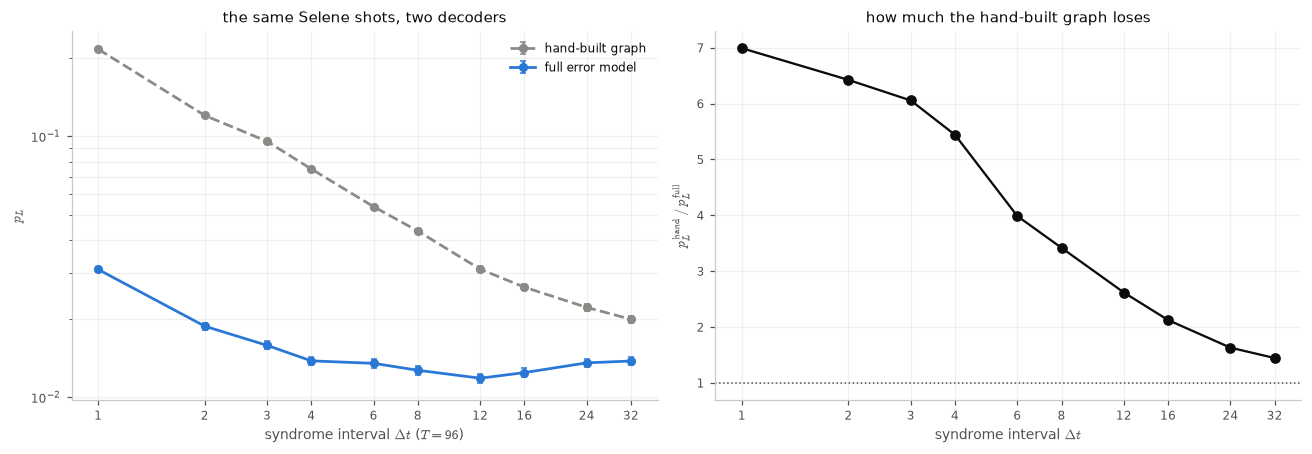

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
ax = axes[0]
for lab, col, ls in (('hand', GRAY, '--'), ('full', BLUE, '-')):
    ax.errorbar(TAUS, DEC[f'{lab} pL'], yerr=DEC[f'{lab} +/-'], marker='o', ms=5, lw=1.8, capsize=2,
                color=col, ls=ls, label={'hand': 'hand-built graph', 'full': 'full error model'}[lab])
tau_axes(ax, TAUS)
ax.set_xlabel(r'syndrome interval $\Delta t$ ($T = 96$)'); ax.set_ylabel(r'$p_L$')
ax.set_title('the same Selene shots, two decoders'); ax.legend()
ax = axes[1]
ax.plot(TAUS, DEC['hand / full'], marker='o', color=INK)
ax.set_xscale('log', base=2); ax.set_xticks(TAUS)
ax.get_xaxis().set_major_formatter(plt.ScalarFormatter()); ax.get_xaxis().set_minor_formatter(plt.NullFormatter())
ax.axhline(1, color=MUTED, lw=1, ls=':'); ax.grid(alpha=.6); ax.set_axisbelow(True)
ax.set_xlabel(r'syndrome interval $\Delta t$'); ax.set_ylabel(r'$p_L^\mathrm{hand}\,/\,p_L^\mathrm{full}$')
ax.set_title('how much the hand-built graph loses')
finish(fig, '06b_hand_vs_full_decoder')

## 3. Why the loss depends on Δt

The hand-built graph models faults that happen *before* a round correctly, and the idle ops
are exactly such faults. Faults *during* extraction produce the diagonal and redistributed
symptoms it lacks. The share of a data qubit's per-round noise that comes from extraction is
`n_data / (n_data + Δt)`, from 87% at Δt = 1 to 18% at Δt = 32. If the missing mechanisms are the
cause, the loss should fall with that share, and with the diagonal share of the error model
(06a §6), towards 1 at large Δt.

In [4]:
def diagonal_share(tau, R):
    nz = len(G.zcols)
    dem = sm.mirror_circuit(G, tau, R, P_1Q, P_MEAS).detector_error_model(decompose_errors=True)
    diag = tot = 0.0
    for inst in dem.flattened():
        if inst.type != 'error':
            continue
        p = inst.args_copy()[0]; tot += p
        dets = [t.val for t in inst.targets_copy() if t.is_relative_detector_id()]
        if len(dets) == 2:
            (r1, c1), (r2, c2) = [(d // nz, d % nz) for d in dets]
            diag += p if (r1 != r2 and c1 != c2) else 0.0
    return diag / tot


why = pd.DataFrame({'extraction share': [G.ops_mean / (G.ops_mean + t) for t in TAUS],
                    'diagonal share of fault probability': [diagonal_share(t, TOTAL_IDLE // t) for t in TAUS],
                    'hand / full': DEC['hand / full'].values}, index=pd.Index(TAUS, name='tau'))
print(why.round(3).to_string())
r_ext = np.corrcoef(why['extraction share'], np.log(why['hand / full']))[0, 1]
r_diag = np.corrcoef(why['diagonal share of fault probability'], np.log(why['hand / full']))[0, 1]
print(f"\ncorrelation with log(hand/full): extraction share {r_ext:.2f}, diagonal share {r_diag:.2f}")

     extraction share  diagonal share of fault probability  hand / full
tau                                                                    
1               0.873                                0.088        6.991
2               0.775                                0.082        6.424
3               0.697                                0.076        6.056
4               0.633                                0.072        5.441
6               0.534                                0.064        3.987
8               0.463                                0.057        3.417
12              0.365                                0.048        2.618
16              0.301                                0.041        2.125
24              0.223                                0.032        1.631
32              0.177                                0.026        1.446

correlation with log(hand/full): extraction share 0.98, diagonal share 1.00


## 4. The same comparison at d = 5

Rotated d = 5 at the same operating point and total idle, generated by
`scripts/circuit_level_generate.py` after the copy passed its checks at d = 5 (06a §6b):
46 blocks × 10,000 shots per Δt, on every divisor of 96 with `N ≥ 5`. Each block was decoded by
both decoders when it was generated; the counts are read back from the cache
(`selene_mirror.decoded`). There is no earlier d = 5 result to reproduce.

In [5]:
G5 = Geometry(CODE, 5)
TAUS5 = [t for t in range(1, TOTAL_IDLE + 1) if TOTAL_IDLE % t == 0 and TOTAL_IDLE // t >= 5]
rows, wins5, nblk5 = [], 0, 0
for t in TAUS5:
    H = M = N = 0
    for k in range(46):
        r = sm.decoded(G5, t, TOTAL_IDLE // t, SHOTS, offset=k * SHOTS, seed=1, p_1q=P_1Q, p_meas=P_MEAS)
        H += r['hand_failures']; M += r['mirror_failures']; N += r['shots']
        wins5 += r['mirror_failures'] < r['hand_failures']; nblk5 += 1
    rows.append({'tau': t, 'R': TOTAL_IDLE // t, 'hand pL': H / N, 'full pL': M / N,
                 'full +/-': np.sqrt(M / N * (1 - M / N) / N), 'hand / full': H / M,
                 'extraction share': G5.ops_mean / (G5.ops_mean + t)})
DEC5 = pd.DataFrame(rows).set_index('tau')
print(DEC5.round(5).to_string())
print(f"\nfull error model has fewer failures in {wins5} of {nblk5} blocks")
print(f"hand / full at the smallest tau: d=3 {DEC['hand / full'].iloc[0]:.1f}, d=5 {DEC5['hand / full'].iloc[0]:.1f}")

      R  hand pL  full pL  full +/-  hand / full  extraction share
tau                                                               
1    96  0.03586  0.00440   0.00010      8.14617           0.89359
2    48  0.02103  0.00304   0.00008      6.92060           0.80766
3    32  0.01702  0.00250   0.00007      6.80609           0.73680
4    24  0.01519  0.00241   0.00007      6.30505           0.67737
6    16  0.01303  0.00244   0.00007      5.34523           0.58328
8    12  0.01197  0.00247   0.00007      4.84257           0.51214
12    8  0.01032  0.00268   0.00008      3.85703           0.41171
16    6  0.00936  0.00309   0.00008      3.02883           0.34421

full error model has fewer failures in 368 of 368 blocks
hand / full at the smallest tau: d=3 7.0, d=5 8.1


## 5. Findings

**1. The hand-built graph is the original 06 decoder, exactly.** Its failure counts on the
stored shots equal the original 06 sweep's cached counts in all 50 blocks, so the comparison is
on the same shots that produced the published curve.

**2. The full error model is better everywhere, by 1.4× to 7.0×.** It has fewer failures in all
50 blocks. The gap is largest at Δt = 1 (`p_L` 0.2162 against 0.0309) and smallest at Δt = 32
(0.0199 against 0.0138).

**3. The gap shrinks as extraction's share of the noise shrinks.** At Δt = 1, 87% of a data
qubit's charged ops per round come from extraction; at Δt = 32, 18%. The hand-built graph models
the remaining idle faults, which happen before a round, correctly, and misreads extraction
faults, whose diagonal and redistributed symptoms it has no edges for (06a §6). `log(hand/full)`
correlates at 0.98 with the extraction share and 1.00 with the diagonal share of fault
probability. Both shares fall monotonically with Δt, so the correlation alone cannot separate
them; the mechanism evidence is the error-model content in 06a.

**4. The decoder changed the conclusion, not just the numbers.** With the hand-built graph,
`p_L` falls monotonically to the largest Δt on the grid, so the original 06 found no interior
optimum. With the full error model, the same shots have a minimum at Δt = 12 (06c). The original
06's "no optimum under Selene's noise" was a property of its decoder.

**5. At d = 5 the gap is larger, and the hand-built graph again hides the optimum.** The full
error model wins all 368 blocks; the ratio runs from 8.1× at Δt = 1 to 3.0× at Δt = 16, against
7.0× to 1.4× at d = 3 over a similar range of extraction share. The hand-built graph's `p_L`
falls all the way to the largest Δt (0.0359 to 0.0094); the full error model has its minimum at
Δt = 4 (06c). The d = 5 error model has a larger diagonal share (14.0% at Δt = 1, 06a §6b), which
fits the larger gap.

### Limits

- **One operating point** for the comparison (rotated, `p_1q = 0.0005`, `p_meas = 0.002`,
  `p_2q = 0`) at d = 3 and 5. The trend of the gap with distance beyond d = 5 is not established.
- **The full error model is still a matching decoder.** It treats fault mechanisms as
  independent and decomposes multi-detector faults into edges; a correlated or
  maximum-likelihood decoder could do better still.
- **The retired 07** (`notebooks/retired/`) used the same hand-built graph and was never
  re-decoded, so its results do not carry over.